# 0 · Basics

**The project.** We have satellite pictures and, for each, a second picture that says what is on the ground at every pixel: water, trees, crops, buildings and so on. We want a model that draws the second picture from the first.

GeoSave opens satellite files as standard Python data objects, ready for PyTorch and Lightning. We will follow one workflow:

Open images → inspect them → prepare tensors → train with Lightning → inspect predictions.

This is ordinary image segmentation. The data is laid out like most segmentation datasets:

```text
data/dynamic_world/
├── train/  images/<id>.tif   labels/<id>.tif
├── val/    ...
└── test/   ...
```

It holds 300 tiles of [Dynamic World](https://doi.org/10.1594/PANGAEA.933475) expert labels, each paired with the Sentinel-2 picture it was drawn on, and is published on the Hugging Face Hub as [fatmur/dynamicworld-300](https://huggingface.co/datasets/fatmur/dynamicworld-300).

Download it into `data/dynamic_world`, next to this notebook. It is about 400 MB; running the cell again only checks for changes.

In [3]:
from pathlib import Path

from huggingface_hub import snapshot_download

root = Path(snapshot_download("fatmur/dynamicworld-300", repo_type="dataset", local_dir="data/dynamic_world"))

Fetching 603 files:   0%|          | 0/603 [00:00<?, ?it/s]

Open one picture and its labels. `gs.open_raster` returns an ordinary `xarray.Dataset`, with one named variable per band. GeoSave adds `.gs` methods for plotting and tensor conversion.

A photo has three bands: red, green and blue. This picture has four: blue, green, red, and near-infrared, light the eye cannot see but plants reflect strongly.

GeoSave reads the RGB band choices and the label's class names and colours from the files, so we can plot them together without choosing colours ourselves.

<xarray.Dataset> Size: 2MB
Dimensions:      (time: 1, x: 510, y: 510)
Coordinates:
  * time         (time) datetime64[ms] 8B 2019-01-30T17:15:41.024000
  * x            (x) float64 4kB 3.703e+05 3.704e+05 ... 3.754e+05 3.754e+05
  * y            (y) float64 4kB 2.229e+06 2.229e+06 ... 2.224e+06 2.224e+06
    spatial_ref  int64 8B 0
Data variables:
    B02          (time, y, x) uint16 520kB dask.array<chunksize=(1, 510, 510), meta=np.ndarray>
    B03          (time, y, x) uint16 520kB dask.array<chunksize=(1, 510, 510), meta=np.ndarray>
    B04          (time, y, x) uint16 520kB dask.array<chunksize=(1, 510, 510), meta=np.ndarray>
    B08          (time, y, x) uint16 520kB dask.array<chunksize=(1, 510, 510), meta=np.ndarray>
Attributes:
    TIFFTAG_IMAGEDESCRIPTION:  The [Sentinel-2](https://sentinel.esa.int/web/...
    TIFFTAG_DATETIME:          2019:01:30 17:15:41
    GEOSAVE_DATETIME:          2019-01-30T17:15:41.024
    id:                        sentinel-2-l2a
    institution:               ESA
    keywords:                  Sentinel, Copernicus, ESA, Satellite, Global, ...
    license:                   proprietary
    stac_groupby:              solar_day
    stac_items:                [{"id":"S2A_MSIL2A_20190130T171541_R112_T14QLH...
    summary:                   The [Sentinel-2](https://sentinel.esa.int/web/...
    title:                     Sentinel-2 Level-2A
    AREA_OR_POINT:             Area

:Layout
   .RGB.I   :RGB   [x,y]   (R,G,B)
   .Image.I :Image   [x,y]   (value)
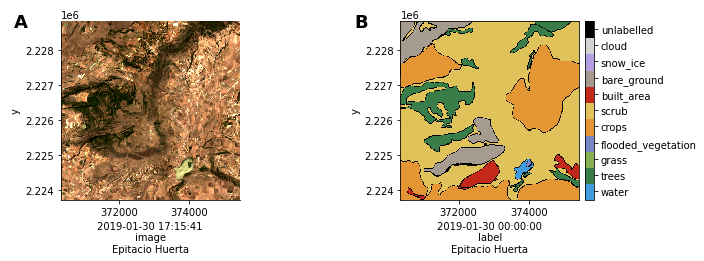

In [4]:
from IPython.display import display

import geosave as gs

images = sorted((root / "train/images").glob("*.tif"))
labels = sorted((root / "train/labels").glob("*.tif"))

image = gs.open_raster(images[0])
label = gs.open_raster(labels[0])

display(image)
gs.stack({"image": image, "label": label}).gs.plot(cols=2)

PyTorch wants tensors. GeoSave's `.gs.to_tensor()` stacks the named bands in dataset order into a tensor shaped `(bands, height, width)`, ready for a plain PyTorch `Dataset` and `DataLoader`. The images and labels folders hold the same file names, so sorting both lists pairs each picture with its labels.

Three details of this data:

- Each picture carries its date as an axis of length one; `.isel(time=0)` takes that one date.
- The pixels are stored as whole numbers, 10,000 times the share of light reflected, so dividing by 10,000 plays the part `/ 255` plays for a photo.
- The label file holds one band, `label`. Taking that band gives a tensor shaped `(height, width)`, the shape a segmentation loss expects.

In [5]:
import torch
from torch.utils.data import DataLoader, Dataset


class Tiles(Dataset):
    def __init__(self, split):
        self.images = sorted((root / split / "images").glob("*.tif"))
        self.labels = sorted((root / split / "labels").glob("*.tif"))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image = gs.open_raster(self.images[index]).isel(time=0)
        label = gs.open_raster(self.labels[index])["label"].isel(time=0)
        pixels = image.gs.to_tensor(dtype="float32") / 10_000  # (4, H, W)
        classes = label.gs.to_tensor(dtype="int64")  # (H, W)
        return pixels, classes


train = Tiles("train")
val = Tiles("val")
train_loader = DataLoader(train, batch_size=8, shuffle=True)
val_loader = DataLoader(val, batch_size=8)

image, label = train[0]
len(train), len(val), image.shape, label.shape

(200, 50, torch.Size([4, 510, 510]), torch.Size([510, 510]))

The model has the three parts most segmentation models have: an encoder that turns pixels into features, a decoder that brings the features back to full size, and a head that scores each of the 10 classes. The encoder halves the height and width and the decoder doubles them, so this tiny model expects even tile dimensions, as this dataset has. Printing the model shows its layers.

In [6]:
from torch import nn


class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(4, 16, 3, stride=2, padding=1), nn.ReLU())

    def forward(self, image):
        return self.net(image)  # (B, 4, H, W) -> (B, 16, H/2, W/2)


class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Upsample(scale_factor=2), nn.Conv2d(16, 16, 3, padding=1), nn.ReLU())

    def forward(self, features):
        return self.net(features)  # (B, 16, H/2, W/2) -> (B, 16, H, W)


class Head(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Conv2d(16, 10, 1)

    def forward(self, features):
        return self.net(features)  # (B, 16, H, W) -> (B, 10, H, W)


model = nn.Sequential(Encoder(), Decoder(), Head())
model

Sequential(
  (0): Encoder(
    (net): Sequential(
      (0): Conv2d(4, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): ReLU()
    )
  )
  (1): Decoder(
    (net): Sequential(
      (0): Upsample(scale_factor=2.0, mode='nearest')
      (1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
    )
  )
  (2): Head(
    (net): Conv2d(16, 10, kernel_size=(1, 1), stride=(1, 1))
  )
)

Training is plain Lightning. First a module that says how a batch is scored. Label 255 marks pixels a labeller left unmarked, so the loss and the metrics ignore it, as segmentation code usually does. The metrics come from [torchmetrics](https://lightning.ai/docs/torchmetrics): mean intersection over union (mIoU), the usual segmentation score, and pixel accuracy.

In [ ]:
import lightning as L
from torchmetrics import MetricCollection
from torchmetrics.classification import MulticlassAccuracy, MulticlassJaccardIndex


class Segmenter(L.LightningModule):
    def __init__(self, model):
        super().__init__()
        self.model = model
        self.val_metrics = MetricCollection(
            {
                "miou": MulticlassJaccardIndex(num_classes=10, ignore_index=255),
                "accuracy": MulticlassAccuracy(num_classes=10, ignore_index=255, average="micro"),
            },
            prefix="val_",
        )
        self.criterion = nn.CrossEntropyLoss(ignore_index=255)

    def forward(self, image):
        return self.model(image)

    def training_step(self, batch, batch_index):
        image, label = batch  # (B, C, H, W), (B, H, W)
        logits = self(image)  # (B, classes, H, W)
        loss = self.criterion(logits, label)
        self.log("train_loss", loss, on_step=True, on_epoch=True)
        return loss

    def validation_step(self, batch, batch_index):
        image, label = batch  # (B, C, H, W), (B, H, W)
        logits = self(image)  # (B, classes, H, W)
        loss = self.criterion(logits, label)
        self.log("val_loss", loss)
        self.val_metrics(logits, label)
        self.log_dict(self.val_metrics)

    def configure_optimizers(self):
        return torch.optim.AdamW(self.parameters(), lr=1e-2)


module = Segmenter(model)
module

Segmenter(
  (model): Sequential(
    (0): Encoder(
      (net): Sequential(
        (0): Conv2d(4, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
        (1): ReLU()
      )
    )
    (1): Decoder(
      (net): Sequential(
        (0): Upsample(scale_factor=2.0, mode='nearest')
        (1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (2): ReLU()
      )
    )
    (2): Head(
      (net): Conv2d(16, 10, kernel_size=(1, 1), stride=(1, 1))
    )
  )
  (val_metrics): MetricCollection(
    (accuracy): MulticlassAccuracy()
    (miou): MulticlassJaccardIndex(),
    prefix=val_
  )
  (criterion): CrossEntropyLoss()
)

Then a Lightning `Trainer` runs six epochs of six training batches and two validation batches each. These integer limits count batches; the loaders stay unchanged. Lightning logs the training loss at every step (`log_every_n_steps=1`) but the validation scores once per epoch, so several epochs give TensorBoard curves rather than single dots. `seed_everything` makes the shuffled batches repeat from run to run.

The cell displays the training loss and validation scores. It takes a couple of minutes on a CPU. Remove the batch limits and increase `max_epochs` when you want to train for longer.

In [8]:
import warnings

from lightning.pytorch.loggers import TensorBoardLogger

# The tiles are small and few; Lightning's hint to add loader workers is noise here.
warnings.filterwarnings("ignore", ".*does not have many workers.*")

L.seed_everything(0)
trainer = L.Trainer(
    max_epochs=6,
    limit_train_batches=6,
    limit_val_batches=2,
    log_every_n_steps=1,
    logger=TensorBoardLogger("lightning_logs", name="", version="basics"),
)
trainer.fit(module, train_loader, val_loader)

Seed set to 0
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
/home/uwu/Projects/geosave-engine/.venv/lib/python3.12/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory lightning_logs/basics/checkpoints exists and is not empty.


┏━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name        ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model       │ Sequential       │  3.1 K │ train │     0 │
│ 1 │ val_metrics │ MetricCollection │      0 │ train │     0 │
│ 2 │ criterion   │ CrossEntropyLoss │      0 │ train │     0 │
└───┴─────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 3.1 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 3.1 K                                                                                                
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 16                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/home/uwu/Projects/geosave-engine/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: 
`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` 
instead.

/home/uwu/Projects/geosave-engine/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: 
`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` 
instead.

`Trainer.fit` stopped: `max_epochs=6` reached.


Lightning logs to TensorBoard, into `lightning_logs/basics/`, named after this notebook so later notebooks' runs sit beside it. Open it here and look at `train_loss_step` against `val_loss` to see whether the model generalises, and at `val_miou` and `val_accuracy` for the score after each epoch.

In [9]:
%load_ext tensorboard
%tensorboard --logdir lightning_logs

Launching TensorBoard...

Predict a validation batch: the model scores every class at every pixel, and `argmax` keeps the best. `gs.raster({"label": ...}, label)` puts our numbers on the label's grid. A variable named `label` keeps the label's class names and colours, so GeoSave plots the two with the same legend.

:Layout
   .Image.I  :Image   [x,y]   (label)
   .Image.II :Image   [x,y]   (prediction)
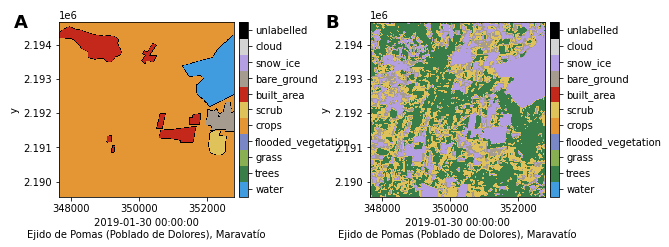

In [10]:
images, _ = next(iter(val_loader))  # (B, C, H, W)
module.eval()
with torch.no_grad():
    logits = module(images)  # (B, classes, H, W)
    # Dim 0 is the batch, so classes are dim 1; [0] keeps the first tile.
    prediction = logits.argmax(dim=1)[0]  # (H, W)

label = gs.open_raster(val.labels[0])["label"].isel(time=0)
codes = prediction.numpy().astype("uint8")
predicted = gs.raster({"label": (("y", "x"), codes)}, label)

label.gs.plot() + predicted.gs.plot()

## What happened

We opened satellite files as xarray Datasets, used GeoSave to plot them and turn their bands into tensors, trained with plain PyTorch and Lightning, and put a prediction back on the tile's grid for comparison.

The displayed metrics and TensorBoard curves show what this run measured. Six short epochs demonstrate the loop, but are too few to judge model quality. Expect poor predictions; train for longer before comparing models.

The rest of the series improves this same project one step at a time:

| Next | Question |
| --- | --- |
| 1 · Model | How do I grow this model, swap its parts and compare runs? |
| 2 · Inputs | What do the four numbers mean, and how do I give the model better inputs? |